[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/langchain-ai/langchain-academy/blob/main/module-2/chatbot-summarization.ipynb) [![Open in LangChain Academy](https://cdn.prod.website-files.com/65b8cd72835ceeacd4449a53/66e9eba12c7b7688aa3dbb5e_LCA-badge-green.svg)](https://academy.langchain.com/courses/take/intro-to-langgraph/lessons/58239436-lesson-5-chatbot-w-summarizing-messages-and-memory)

# Chatbot with message summarization

## Review

We've covered how to customize graph state schema and reducer. 
 
We've also shown a number of ways to trim or filter messages in graph state. 

## Goals

Now, let's take it one step further! 

Rather than just trimming or filtering messages, we'll show how to use LLMs to produce a running summary of the conversation.
 
This allows us to retain a compressed representation of the full conversation, rather than just removing it with trimming or filtering.

We'll incorporate this summarization into a simple Chatbot.  

And we'll equip that Chatbot with memory, supporting long-running conversations without incurring high token cost / latency. 

In [1]:
%%capture --no-stderr
%pip install --quiet -U langchain_core langgraph langchain-google-genai python-dotenv


In [5]:
import os, getpass
try:
    from dotenv import load_dotenv
    load_dotenv()
except ImportError:
    pass

def _set_env(var: str):
    if not os.environ.get(var):
        os.environ[var] = getpass.getpass(f"{var}: ")

_set_env("GEMINI_API_KEY")
if os.environ.get("GEMINI_API_KEY") and not os.environ.get("GOOGLE_API_KEY"):
    os.environ["GOOGLE_API_KEY"] = os.environ["GEMINI_API_KEY"]


We'll use [LangSmith](https://docs.langchain.com/langsmith/home) for  [tracing](https://docs.langchain.com/langsmith/observability-concepts).

In [6]:
_set_env("LANGSMITH_API_KEY")
os.environ["LANGSMITH_TRACING"] = "true"
os.environ["LANGSMITH_PROJECT"] = "langchain-academy"

In [7]:
from langchain_google_genai import ChatGoogleGenerativeAI
model = ChatGoogleGenerativeAI(model="gemini-3.5-flash", temperature=0)


Both GOOGLE_API_KEY and GEMINI_API_KEY are set. Using GOOGLE_API_KEY.


We'll use `MessagesState`, as before.

In addition to the built-in `messages` key, we'll now include a custom key (`summary`).

In [8]:
from langgraph.graph import MessagesState
class State(MessagesState):
    summary: str

We'll define a node to call our LLM that incorporates a summary, if it exists, into the prompt.

In [9]:
from langchain_core.messages import SystemMessage, HumanMessage, RemoveMessage

# Define the logic to call the model
def call_model(state: State):
    
    # Get summary if it exists
    summary = state.get("summary", "")

    # If there is summary, then we add it
    if summary:
        
        # Add summary to system message
        system_message = f"Summary of conversation earlier: {summary}"

        # Append summary to any newer messages
        messages = [SystemMessage(content=system_message)] + state["messages"]
    
    else:
        messages = state["messages"]
    
    response = model.invoke(messages)
    return {"messages": response}

We'll define a node to produce a summary.

Note, here we'll use `RemoveMessage` to filter our state after we've produced the summary.

In [11]:
def summarize_conversation(state: State):
    
    # First, we get any existing summary
    summary = state.get("summary", "")

    # Create our summarization prompt 
    if summary:
        
        # A summary already exists
        summary_message = (
            f"This is summary of the conversation to date: {summary}\n\n"
            "Extend the summary by taking into account the new messages above:"
        )
        
    else:
        summary_message = "Create a summary of the conversation above:"

    # Add prompt to our history
    messages = state["messages"] + [HumanMessage(content=summary_message)]
    response = model.invoke(messages)
    
    # Delete all but the 2 most recent messages
    delete_messages = [RemoveMessage(id=m.id) for m in state["messages"][:-2]]
    return {"summary": response.content, "messages": delete_messages}

We'll add a conditional edge to determine whether to produce a summary based on the conversation length.

In [12]:
from langgraph.graph import END
from typing_extensions import Literal
# Determine whether to end or summarize the conversation
def should_continue(state: State) -> Literal ["summarize_conversation",END]:
    
    """Return the next node to execute."""
    
    messages = state["messages"]
    
    # If there are more than six messages, then we summarize the conversation
    if len(messages) > 6:
        return "summarize_conversation"
    
    # Otherwise we can just end
    return END

## Adding memory

Recall that [state is transient](https://github.com/langchain-ai/langgraph/discussions/352#discussioncomment-9291220) to a single graph execution.

This limits our ability to have multi-turn conversations with interruptions. 

As introduced at the end of Module 1, we can use [persistence](https://docs.langchain.com/oss/python/langgraph/persistence) to address this! 
 
LangGraph can use a checkpointer to automatically save the graph state after each step.

This built-in persistence layer provides memory, allowing LangGraph to resume from the last state update. 

As we previously showed, one of the easiest to work with is `MemorySaver`, an in-memory key-value store for Graph state.

All we need to do is compile the graph with a checkpointer, and our graph has memory!

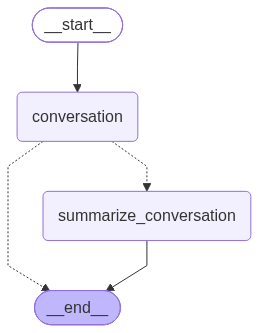

In [13]:
from IPython.display import Image, display
from langgraph.checkpoint.memory import MemorySaver
from langgraph.graph import StateGraph, START

# Define a new graph
workflow = StateGraph(State)
workflow.add_node("conversation", call_model)
workflow.add_node(summarize_conversation)

# Set the entrypoint as conversation
workflow.add_edge(START, "conversation")
workflow.add_conditional_edges("conversation", should_continue)
workflow.add_edge("summarize_conversation", END)

# Compile
memory = MemorySaver()
graph = workflow.compile(checkpointer=memory)
display(Image(graph.get_graph().draw_mermaid_png()))

## Threads

The checkpointer saves the state at each step as a checkpoint.

These saved checkpoints can be grouped into a `thread` of conversation.

Think about Slack as an analog: different channels carry different conversations.

Threads are like Slack channels, capturing grouped collections of state (e.g., conversation).

Below, we use `configurable` to set a thread ID.

![state.jpg](https://cdn.prod.website-files.com/65b8cd72835ceeacd4449a53/66dbadf3b379c2ee621adfd1_chatbot-summarization1.png)

In [14]:
# Create a thread
config = {"configurable": {"thread_id": "1"}}

# Start conversation
input_message = HumanMessage(content="hi! I'm Lance")
output = graph.invoke({"messages": [input_message]}, config) 
for m in output['messages'][-1:]:
    m.pretty_print()

input_message = HumanMessage(content="what's my name?")
output = graph.invoke({"messages": [input_message]}, config) 
for m in output['messages'][-1:]:
    m.pretty_print()

input_message = HumanMessage(content="i like the 49ers!")
output = graph.invoke({"messages": [input_message]}, config) 
for m in output['messages'][-1:]:
    m.pretty_print()

================================== Ai Message ==================================

[{'type': 'text', 'text': 'Hi Lance! Nice to meet you. How can I help you today?', 'extras': {'signature': 'EpAHCo0HAWkUfRO0F65Wp5tr4eNWSMeVk8GpNBaZ5F2JqRCwGp9a3JG2NiP9WS7jEp10G+vcbtidm8OHxRAEJoMyslArbjljgI1abbEOypcN+TTsQX8bQhnwSdJVnMFSxtvwrPgRY/6AjTwasHZr5eU5RImaOsETEA/O5cKYMtvqnehpNTxamsWqYQjRWkgSbYdbC/4q3fR0ALEiwd2gz4zfnZgWr9qD8tmWfHX9z/MJ4YRsTb+h3zOd8Y89DjQTNs1I/vV86sy6ZTYqNP/QIlQXNH3XMtv4nbi7zVWKPNhBUzIn5Vwf2mZrFrHDZ3GTVSj5ApFxxR8pleQuQCMB7f41sWtE65+vRrbWXdO0azReNDWundsQ+qDI2w/yIUkkj9Cr43Z7g93sKrYK05XWYP5kgGQF8jKsOHq48ZNC+wLvNoYm60jF56l8ekLvUE0Kq78H6NtFlDLow1tSDT9VkCWrRtalf1i1ggQrCDjQcpTVeWsBEi4Ar/RTm9YMrizp2ZbeD5hf5Zo1tBfnU5cI0IVzKznt4C4NVy1KKwMM79OVdyWFHkYdQrvljKpoW9Z528qIuraUgSfS9k1z8KglKufXIHeXD/DnqtNmTYNPPEJRg0VvEGitTGrav5DNULjjAIhIhifSL6ITyIoJ8qYfUGjGCrn7WZKO0LP+TVNgoERCzmnPB03FaOBxN05cWUtvRTerk9TwOyww2hgyg2yT/PF91ysjWAsfSeoFC0qpdhSKyEiyvx8YwEAPUd+HLr8n/EEPbu8G76XnIu3cqrZyGydgnFDW25nNwPTuoq7DDR

Now, we don't yet have a summary of the state because we still have < = 6 messages.

This was set in `should_continue`. 

```
    # If there are more than six messages, then we summarize the conversation
    if len(messages) > 6:
        return "summarize_conversation"
```

We can pick up the conversation because we have the thread.

In [15]:
graph.get_state(config).values.get("summary","")

''

The `config` with thread ID allows us to proceed from the previously logged state!

In [16]:
input_message = HumanMessage(content="i like Nick Bosa, isn't he the highest paid defensive player?")
output = graph.invoke({"messages": [input_message]}, config) 
for m in output['messages'][-1:]:
    m.pretty_print()

================================== Ai Message ==================================

[{'type': 'text', 'text': 'Yes, he is! In September 2023, Nick Bosa signed a massive 5-year, $170 million contract extension with the 49ers. \n\nThat averages out to **$34 million per year** (with over $122 million guaranteed), which made him the highest-paid defensive player in NFL history!\n\nHe definitely earned it, too—winning the NFL Defensive Player of the Year award in 2022 and being a total nightmare for opposing quarterbacks. His famous shrug celebration after a sack is iconic!', 'extras': {'signature': 'ErcSCrQSAWkUfRNAfNBWsfNe58hAkf/RTU0zo6Ql0AacvHz2erXWye/FI1uJyUc4iA3706fQiNZx+Sbyv5WJ0fbXZ/J4vPiRdwsod4nwXk5qcOdWcSPTPnU+IDR0Xv2bmyofW09C4NHrdVqeTKhy4H9xqDEs0npoJRbyoUzqsuCXLgGNCiYJh35EStCgwwAd1wALuxajBESr6YLOKbxNB8I2eiem8GMaANOVa07pp5ng+ag3BwUnOfkLYiIRQQN6vtoFeGAZda7ZcBqcHoqgKyIljl4C6jFU39y3RvaOEfNXwyE3GXbPnOwEVOH4lQjOAGFkClYDcxJ/Eh3fjb/rgHdCMuWcUmC8Cas0ZXLGve8vCruPwSPvLrqbxd2qn8OGpowVFyucVsvTNX4

In [17]:
graph.get_state(config).values.get("summary","")

[{'type': 'text',
  'text': 'Here is a summary of our conversation so far:\n\n* **Introduction:** You introduced yourself as **Lance**.\n* **Favorite Team:** You shared that you are a fan of the **San Francisco 49ers**.\n* **Favorite Player & Contract Fact:** You mentioned liking defensive end **Nick Bosa** and asked about his contract. \n* **Details Confirmed:** We discussed how Bosa became the highest-paid defensive player in NFL history after signing a 5-year, $170 million extension ($34 million/year) in September 2023, following his 2022 Defensive Player of the Year season.',
  'extras': {'signature': 'EtAMCs0MAWkUfRMqzFUggtzADhtTB2Udeg8D2wZFt1zqDbKX1eiDCFNh/exWwKxjzSz4rVcfkuuQr8ulgoh2fY9D8LasV7thf8qG2ZnwGgTvvs+Bs6XEftGGTm80N/nPDCn6+pGkOPMRJOhgowzReoDtYB2DP+1SjgBN9A4ennJNryyaHf61DkAWuCh2RDdOycbh8HE0pIYOtI7Rmk6IFFZ4AakNPMPkhaqvR6EaoeF3cWt77Y7fOqRcSTFCsxmt+jQRpZRT+7a0/UBVSvdLc4A7/YoSJpbCa4pnBAxStdgmDTtwtaKNZdFPgpy2IeQgYotyE46XYv/tRRxhtjSCTefxm2rXXe3ecP1U3o/IdJJXUMOgIbrVHEbL3jj+tU/XO2

## LangSmith

Let's review the trace!